In [1]:
import torch
import copy
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from ep06_plots import show_book, show_history, show_boundary, show_sizes
print(torch.__version__)

2.13.0+cu130


In [2]:
## Let's create a moon dataset

X, y = make_moons(n_samples=1200, noise = 0.3, random_state=42)
X = torch.tensor(X, dtype = torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1,1)

X.shape

torch.Size([1200, 2])

In [3]:
X_train, y_train = X[:100], y[:100].clone()  # Practice book
X_val, y_val = X[100:200], y[100:200]        # mock test
X_test, y_test = X[200:], y[200:]            # board exam


Misprinted questions:  [45, 15, 90, 32, 35, 63, 17, 72, 79, 96]


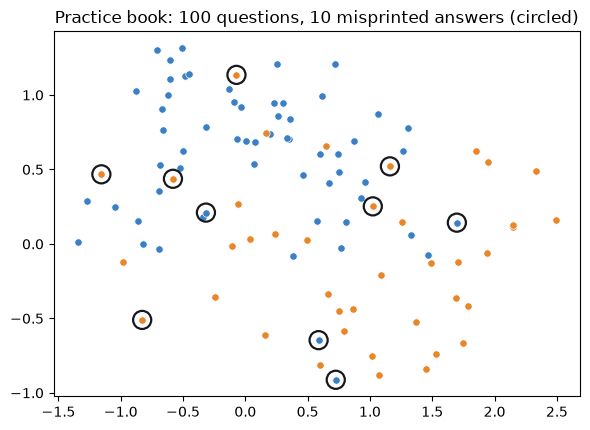

In [4]:
torch.manual_seed(1)
wrong = torch.randperm(100)[:10]
y_train[wrong] = 1 - y_train[wrong]

print("Misprinted questions: ", wrong.tolist())

train_data = TensorDataset(X_train, y_train)
show_book(X_train, y_train, wrong)

In [5]:
def new_big_model():
    return nn.Sequential(
        nn.Linear(2, 200), nn.ReLU(),
        nn.Linear(200, 200), nn.ReLU(),
        nn.Linear(200,1),
    )

knobs = sum(p.numel() for p in new_big_model().parameters())
print("Knobs (weights and biases):", knobs)
print("Practice questions: ", len(X_train))

Knobs (weights and biases): 41001
Practice questions:  100


In [6]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    losses = []
    for xb, yb in loader:
        prediction = model(xb)
        loss = loss_fn(prediction, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

In [7]:
loss_fn = nn.BCEWithLogitsLoss()

def evaluate(model, X, y):
    model.eval()                             # exam mode 
    with torch.no_grad():
        scores = model(X)
        loss = loss_fn(scores, y).item()
        acc = ((scores > 0).float() == y).float().mean().item()
    model.train()                             # back to study mode
    return round(loss, 3), round(acc, 3)

In [8]:
torch.manual_seed(42)
model = new_big_model()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)
loader = DataLoader(train_data, batch_size = 32, shuffle = True)

history = {"practice": [], 'mock': []}
for epoch in range(1, 501):
    train_one_epoch(model , loader, loss_fn, optimizer)

    history['practice'].append(evaluate(model, X_train, y_train)[0])
    history['mock'].append(evaluate(model, X_val, y_val)[0])
print("pactice book: ", evaluate(model, X_train, y_train))
print("Mock test: ", evaluate(model, X_val, y_val))

pactice book:  (0.088, 0.97)
Mock test:  (1.43, 0.79)


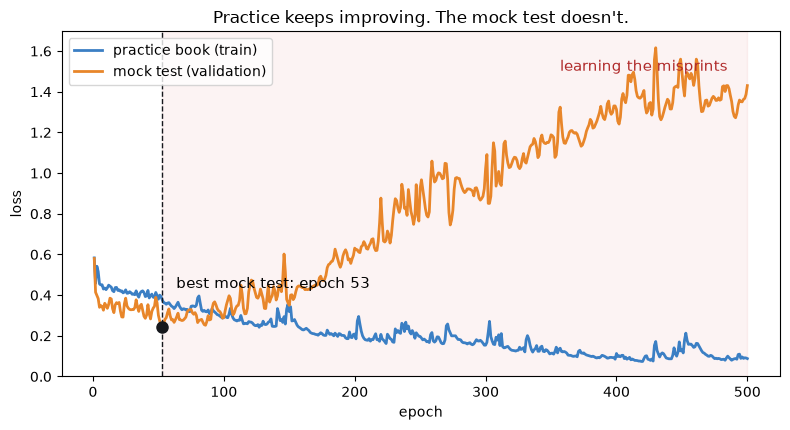

In [9]:
show_history(history)

Misprints the model learnt by hear:  10 of 10


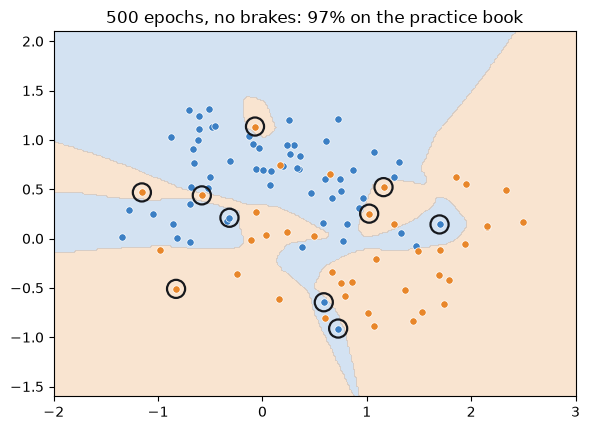

In [10]:
## How did the model read the misprints

with torch.no_grad():
    says = (model(X_train[wrong]) > 0).float()
memorized = int((says == y_train[wrong]).sum())
print("Misprints the model learnt by hear: ", memorized, 'of 10')
show_boundary(model, X_train, y_train, wrong, "500 epochs, no brakes")

In [11]:
## Best mock test performance

best_epoch = history['mock'].index(min(history['mock'])) + 1
print("best mock test: epoch", best_epoch, "| loss", min(history['mock']))
print("mock test at epoch 500: loss", history['mock'][-1])

best mock test: epoch 53 | loss 0.244
mock test at epoch 500: loss 1.43


## Early stopping

In [12]:
torch.manual_seed(42)
model_es = new_big_model()
optimizer = torch.optim.Adam(model_es.parameters(), lr = 0.01)
loader = DataLoader(train_data, batch_size = 32, shuffle = True)

best_loss, best_state = 999, None
patience, bad_epoch = 50, 0


In [13]:
for epoch in range(1, 501):
    train_one_epoch(model_es, loader, loss_fn, optimizer)
    val_loss = evaluate(model_es, X_val, y_val)[0]
    if val_loss < best_loss:
        best_loss, best_epoch, bad_epochs = val_loss, epoch, 0
        best_state = copy.deepcopy(model_es.state_dict())   ## Snapshot of the model
    else:
        bad_epochs += 1
    if bad_epoch == patience:
        print("Stoped at epoch", epoch, "| best was epoch: ", best_epoch)
        break

In [14]:
print(best_epoch)

53


Practice book:  (0.376, 0.84)
mock test:  (0.244, 0.9)


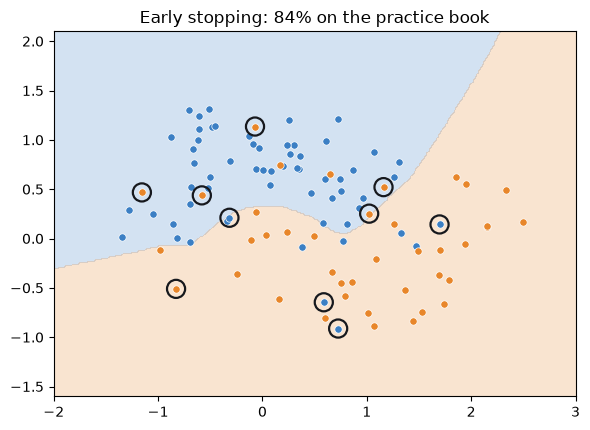

In [15]:
model_es.load_state_dict(best_state)
torch.save(best_state, 'best_model.pt')
print("Practice book: ", evaluate(model_es, X_train, y_train))
print("mock test: ", evaluate(model_es, X_val, y_val))
show_boundary(model_es, X_train, y_train, wrong, "Early stopping")

practice book:  (0.325, 0.86)
mock test    :  (0.279, 0.89)


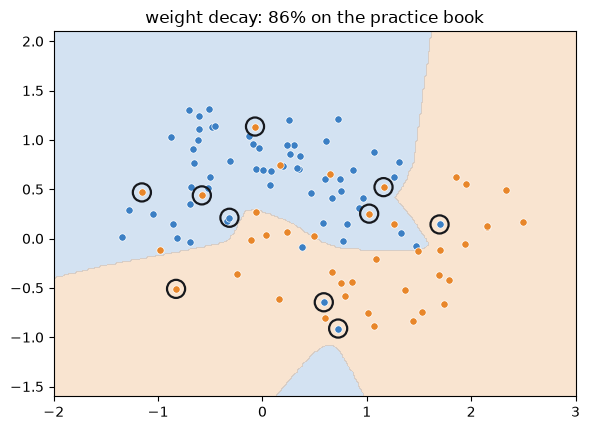

In [16]:
torch.manual_seed(42)
model_wd = new_big_model()
optimizer = torch.optim.Adam(model_wd.parameters(), lr = 0.01,
                             weight_decay=0.001)    # only adding weight decay
loader = DataLoader(train_data, batch_size=32, shuffle=True)
for epoch in range(1, 501):
    train_one_epoch(model_wd, loader, loss_fn, optimizer)

print("practice book: ", evaluate(model_wd, X_train, y_train))
print("mock test    : ", evaluate(model_wd, X_val, y_val))
show_boundary(model_wd, X_train, y_train, wrong, "weight decay")

## Dropout

In [17]:
def new_dropout_model():
    return nn.Sequential(
        nn.Linear(2, 200), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(200, 200), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(200,1),
    )



In [18]:
torch.manual_seed(42)
model_do = new_dropout_model()
point = X_train[:1]        # one practice question
with torch.no_grad():
    print("Study mode: ", model_do(point), model_do(point))
    model_do.eval()                                             # Dropout goes OFF
    print("Exam mode: ", model_do(point), model_do(point))
    model_do.train()


Study mode:  tensor([[0.0378]]) tensor([[-0.2814]])
Exam mode:  tensor([[-0.5152]]) tensor([[-0.5152]])


practice book:  (0.324, 0.87)
Mock test    :  (0.265, 0.88)


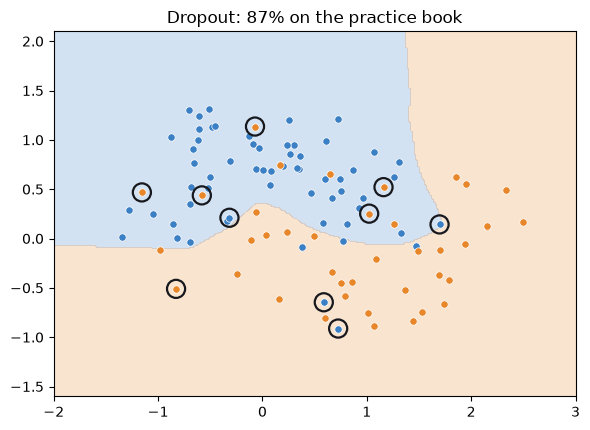

In [19]:
torch.manual_seed(42)
model_do = new_dropout_model()
optimizer = torch.optim.Adam(model_do.parameters(), lr = 0.01)
loader = DataLoader(train_data, batch_size = 32, shuffle=True)
for epoch in range(1, 501):
    train_one_epoch(model_do, loader, loss_fn, optimizer)
print("practice book: ", evaluate(model_do, X_train, y_train))
print("Mock test    : ", evaluate(model_do, X_val, y_val))
show_boundary(model_do, X_train, y_train, wrong, "Dropout")


## Final exam: Board exam

In [20]:
models = {"no brakes": model, "early stopping": model_es,
          "weight decay": model_wd, "dropout": model_do}
for name, m in models.items():
    practice = evaluate(m, X_train, y_train)[1]
    exam = evaluate(m, X_test, y_test)[1]
    print(name, "| practice book", practice, "| board exam", exam)

no brakes | practice book 0.97 | board exam 0.771
early stopping | practice book 0.84 | board exam 0.873
weight decay | practice book 0.86 | board exam 0.869
dropout | practice book 0.87 | board exam 0.876


## Research labs

In [21]:
X_lab, y_lab = make_moons(n_samples=1000, noise = 0.3, random_state=42)
X_lab = torch.tensor(X_lab, dtype = torch.float32)
y_lab = torch.tensor(y_lab, dtype = torch.float32).reshape(-1,1)
print("lab exam: ", len(X_lab), "new questions")



lab exam:  1000 new questions


In [22]:
for name in ['early stopping', 'weight decay']:
    m = models[name]
    scores = []
    for i in range(0, 1000, 100):
        scores.append(evaluate(m, X_lab[i: i+100], y_lab[i: i + 100])[1])
    print(name, "| 10 mock tests: ", min(scores), "to", max(scores))
    print(" all 1000 at once: ", evaluate(m, X_lab, y_lab))

early stopping | 10 mock tests:  0.82 to 0.96
 all 1000 at once:  (0.318, 0.874)
weight decay | 10 mock tests:  0.8 to 0.91
 all 1000 at once:  (0.32, 0.877)


In [23]:
torch.manual_seed(0)
drop = nn.Dropout(0.5)
print("Study mode: ", drop(torch.ones(1, 10)))

many = drop(torch.ones(1, 100_000))
print("swithced off: ", round((many == 0).float().mean().item(), 3))
print("Average signal: ", round(many.mean().item(), 3))


drop.eval()
print("Exam mode: ", drop(torch.ones(1,10)))

Study mode:  tensor([[0., 0., 2., 0., 0., 0., 2., 2., 0., 2.]])
swithced off:  0.501
Average signal:  0.999
Exam mode:  tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


In [24]:
torch.ones(1, 10)

tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [25]:
def weight_size(m):
    total = sum((p**2).sum() for p in m.parameters())
    return round(total.sqrt().item(), 1)

torch.manual_seed(0)
print("Before studying | weight size", weight_size(new_big_model()))
for name, m in models.items():
    print(name, "| weight size: ", weight_size(m))

Before studying | weight size 13.1
no brakes | weight size:  62.5
early stopping | weight size:  24.3
weight decay | weight size:  9.4
dropout | weight size:  54.1


In [26]:
def study(model, data, epochs=500, lr=0.01, batch_size=32):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(data, batch_size=batch_size, shuffle=True)
    for epoch in range(epochs):
        train_one_epoch(model, loader, loss_fn, optimizer)
    return model
torch.manual_seed(0)
again = study(new_big_model(), train_data)
print("cell 7 again | mock test:", evaluate(again, X_val, y_val))

cell 7 again | mock test: (1.038, 0.79)


Practice book:  (0.032, 1.0)
Lab exam:  (5.555, 0.415)


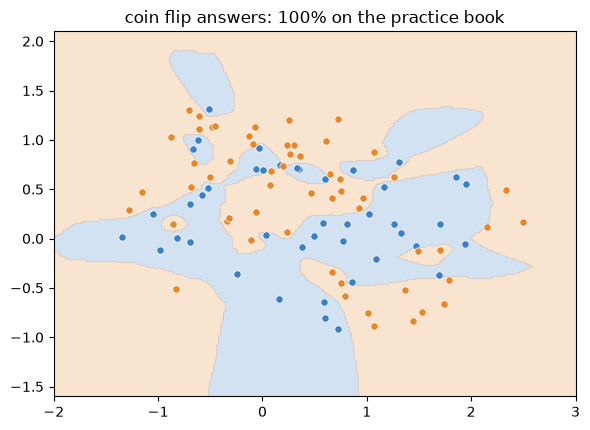

In [27]:
torch.manual_seed(0)
y_coin = torch.randint(0,2, (100,1)).float()
coin_data = TensorDataset(X_train, y_coin)
model_coin = study(new_big_model(), coin_data, epochs = 1000,
                   lr = 0.003, batch_size=100)
print("Practice book: ", evaluate(model_coin, X_train, y_coin))
print("Lab exam: ", evaluate(model_coin, X_lab, y_lab))
show_boundary(model_coin, X_train, y_coin, title = "coin flip answers")

In [28]:
def new_model(width):
    return nn.Sequential(
        nn.Linear(2, width), nn.ReLU(),
        nn.Linear(width, width), nn.ReLU(),
        nn.Linear(width, 1),
    )

1 neurons|  7 knobs | 0.6 | 0.5
2 neurons|  15 knobs | 0.79 | 0.843
4 neurons|  37 knobs | 0.81 | 0.848
8 neurons|  105 knobs | 0.85 | 0.86
16 neurons|  337 knobs | 0.86 | 0.886
32 neurons|  1185 knobs | 0.96 | 0.797
64 neurons|  4417 knobs | 0.91 | 0.811
128 neurons|  17025 knobs | 0.96 | 0.767
200 neurons|  41001 knobs | 0.99 | 0.786


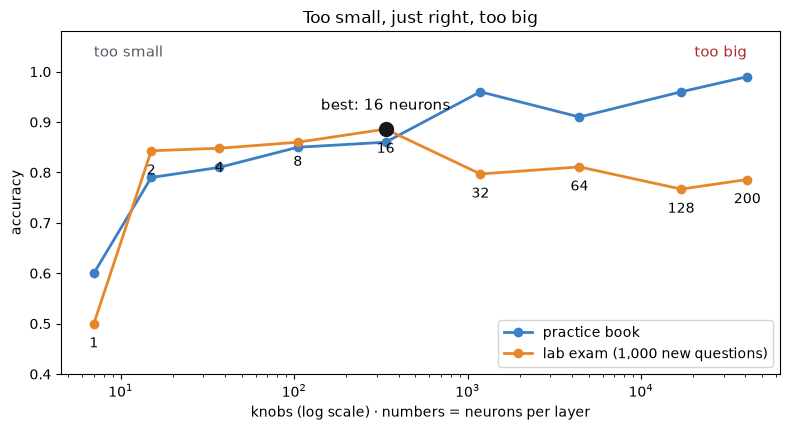

In [29]:
results = []
for width in [1, 2, 4, 8, 16, 32, 64, 128, 200]:
    torch.manual_seed(0)
    n = study(new_model(width), train_data)
    knobs = sum(p.numel() for p in n.parameters())
    practice = evaluate(n, X_train, y_train)[1]
    lab = evaluate(n, X_lab, y_lab)[1]
    results.append((width, knobs, practice, lab))
    print(width, "neurons| ", knobs, "knobs |", practice, "|", lab)
show_sizes(results)